<a href="https://colab.research.google.com/github/arman-hossain45/Convolution-Neural-Network/blob/main/pneomonia_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
train_dir = "/content/drive/MyDrive/train"
test_dir = "/content/drive/MyDrive/test"

In [ ]:
import os

print(os.listdir(train_dir))
print(os.listdir(test_dir))

['opacity', 'normal']
['opacity', 'normal']


In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.Grayscale(num_output_channels=3), # RGB তে convert
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [ ]:
train_dataset = datasets.ImageFolder(
    root=train_dir,
    transform=transform
)

test_dataset = datasets.ImageFolder(
    root=test_dir,
    transform=transform
)

In [ ]:
print(train_dataset.classes)

['normal', 'opacity']


In [ ]:
print(test_dataset.classes)

['normal', 'opacity']


In [ ]:
print(train_dataset.class_to_idx)

{'normal': 0, 'opacity': 1}


In [ ]:
print(len(train_dataset))
print(len(test_dataset))

3313
624


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

In [ ]:
images, labels = next(iter(train_loader))

print(images.shape)# batch = 32 ,RGB =3, size = 224*224
print(labels.shape)

torch.Size([32, 3, 224, 224])
torch.Size([32])


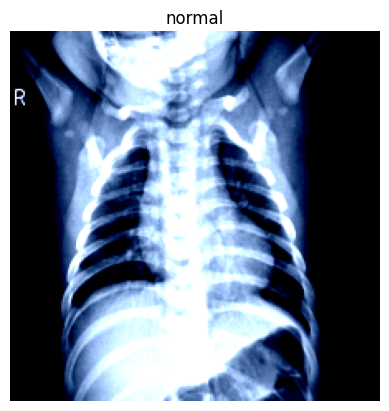

In [ ]:
import matplotlib.pyplot as plt

image = images[0]
image = image.permute(1,2,0)

plt.imshow(image)
plt.title(train_dataset.classes[labels[0]])
plt.axis('off')
plt.show()

In [ ]:
import torch
import torch.nn as nn

class MyNN(nn.Module):
    def __init__(self, input_channels=3):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(input_channels, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.MaxPool2d(2,2),     # 224 -> 112

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.MaxPool2d(2,2),     # 112 -> 56

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.MaxPool2d(2,2)      # 56 -> 28
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(128 * 28 * 28, 512),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(128,64),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(64, 2)       # normal and opacity
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [ ]:
learning_rate = 0.001
epochs = 80

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = MyNN(3)# gray scale image for tHat reason i apply 1 if here RGB images than i apply 3
model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate,
    weight_decay=1e-4
)

In [ ]:
# training loop

for epoch in range(epochs):

  total_epoch_loss = 0

  for batch_features, batch_labels in train_loader:

    # move data to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    # forward pass
    outputs = model(batch_features)

    # calculate loss
    loss = criterion(outputs, batch_labels)

    # back pass
    optimizer.zero_grad()
    loss.backward()

    # update grads
    optimizer.step()

    total_epoch_loss = total_epoch_loss + loss.item()

  avg_loss = total_epoch_loss/len(train_loader)
  print(f'Epoch: {epoch + 1} , Loss: {avg_loss}')

Epoch: 1 , Loss: 0.3183743750425772
Epoch: 2 , Loss: 0.12908024986525282
Epoch: 3 , Loss: 0.09593591292370827
Epoch: 4 , Loss: 0.08269176596681624
Epoch: 5 , Loss: 0.049602559484250935
Epoch: 6 , Loss: 0.051427507283348786
Epoch: 7 , Loss: 0.04819918200947681
Epoch: 8 , Loss: 0.07102180454244962
Epoch: 9 , Loss: 0.05843739317581891
Epoch: 10 , Loss: 0.04005065644668093
Epoch: 11 , Loss: 0.035825444844949046
Epoch: 12 , Loss: 0.02279485784474061
Epoch: 13 , Loss: 0.03267532286319973
Epoch: 14 , Loss: 0.0275922918088025
Epoch: 15 , Loss: 0.04382895310223052
Epoch: 16 , Loss: 0.06759037317491536
Epoch: 17 , Loss: 0.02131107064797805
Epoch: 18 , Loss: 0.01502675744561406
Epoch: 19 , Loss: 0.034799029421615627
Epoch: 20 , Loss: 0.06942648582382123
Epoch: 21 , Loss: 0.0299147247167359
Epoch: 22 , Loss: 0.02404452372892999
Epoch: 23 , Loss: 0.025385910680494013
Epoch: 24 , Loss: 0.013349979467951491
Epoch: 25 , Loss: 0.02689470850675235
Epoch: 26 , Loss: 0.01672716498228073
Epoch: 27 , Loss: 

In [ ]:

model.eval()


MyNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=100352, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p

In [ ]:

# evaluation on test data
total = 0
correct = 0

with torch.no_grad():

  for batch_features, batch_labels in test_loader:

    # move data to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    outputs = model(batch_features)

    _, predicted = torch.max(outputs, 1)

    total = total + batch_labels.shape[0]

    correct = correct + (predicted == batch_labels).sum().item()

print(correct/total)

0.717948717948718


In [ ]:

# evaluation on test data
total = 0
correct = 0

with torch.no_grad():

  for batch_features, batch_labels in train_loader:

    # move data to gpu
    batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

    outputs = model(batch_features)

    _, predicted = torch.max(outputs, 1)

    total = total + batch_labels.shape[0]

    correct = correct + (predicted == batch_labels).sum().item()

print(correct/total)

In [ ]:


transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

train_dataset = datasets.ImageFolder(
    root=train_dir,
    transform=transform
)

test_dataset = datasets.ImageFolder(
    root=test_dir,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

In [ ]:


from torchvision import models
from torchvision.models import VGG16_Weights

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vgg16 = models.vgg16(weights=VGG16_Weights.DEFAULT)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:05<00:00, 101MB/s]


In [ ]:
for param in vgg16.features.parameters():
    param.requires_grad = False

In [ ]:
vgg16.classifier = nn.Sequential(

           nn.Linear(25088,1024),
           nn.ReLU(),
           nn.Dropout(0.4),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(128,64),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(64, 2)
)

vgg16 = vgg16.to(device)

In [ ]:
vgg16.eval()

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [ ]:
learning_rate = 0.0001
epochs = 100

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    vgg16.classifier.parameters(),
    lr=learning_rate,
    weight_decay=1e-4
)

In [ ]:
for epoch in range(epochs):

    vgg16.train()

    running_loss = 0

    for batch_features, batch_labels in train_loader:

        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        outputs = vgg16(batch_features)

        loss = criterion(outputs, batch_labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{epochs}] Loss : {running_loss/len(train_loader):.4f}")

RuntimeError: mat1 and mat2 shapes cannot be multiplied (32x1024 and 512x256)

In [ ]:
vgg16.eval()

correct = 0
total = 0

with torch.no_grad():

    for batch_features, batch_labels in test_loader:

        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        outputs = vgg16(batch_features)

        _, predicted = torch.max(outputs,1)

        total += batch_labels.size(0)

        correct += (predicted == batch_labels).sum().item()

print(f"VGG16 Test Accuracy : {100*correct/total:.2f}%")

In [ ]:
correct = 0
total = 0

vgg16.eval()

with torch.no_grad():

    for batch_features, batch_labels in train_loader:

        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        outputs = vgg16(batch_features)

        _, predicted = torch.max(outputs,1)

        total += batch_labels.size(0)

        correct += (predicted == batch_labels).sum().item()

print(f"VGG16 Train Accuracy : {100*correct/total:.2f}%")

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    roc_auc_score
)

import matplotlib.pyplot as plt
import numpy as np

In [ ]:
model.eval()      # For Custom CNN
# vgg16.eval()    # For VGG16

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)      # Replace model with vgg16 for VGG16

        _, predicted = torch.max(outputs,1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_dataset.classes
)

plt.figure(figsize=(4,4))
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
model.eval()

all_labels = []
all_probs = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)      # Replace model with vgg16

        probabilities = torch.softmax(outputs, dim=1)

        all_probs.extend(probabilities[:,1].cpu().numpy())

        all_labels.extend(labels.numpy())

fpr, tpr, thresholds = roc_curve(all_labels, all_probs)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
auc_score = roc_auc_score(all_labels, all_probs)

print("AUC Score :", auc_score)

In [ ]:
fig, ax = plt.subplots(1,2, figsize=(8,4))

#######################
# Confusion Matrix
#######################

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_dataset.classes
)

disp.plot(ax=ax[0], cmap="Blues")

ax[0].set_title("Confusion Matrix")

#######################
# ROC Curve
#######################

ax[1].plot(fpr, tpr,
           label=f"AUC={roc_auc:.4f}",
           linewidth=2)

ax[1].plot([0,1],[0,1],'k--')

ax[1].set_xlabel("False Positive Rate")

ax[1].set_ylabel("True Positive Rate")

ax[1].set_title("ROC Curve")

ax[1].legend()

plt.tight_layout()

plt.show()

In [ ]:
!pip install grad-cam

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

In [ ]:
for param in vgg16.parameters():
    param.requires_grad = True

In [ ]:
image_tensor, label = test_dataset[0]

input_tensor = image_tensor.unsqueeze(0).to(device)

input_tensor.requires_grad_()

In [ ]:
output = vgg16(input_tensor)

prediction = output.argmax(dim=1).item()

print("Prediction :", train_dataset.classes[prediction])
print("Ground Truth :", train_dataset.classes[label])

In [ ]:
target_layers = [vgg16.features[28]]

In [ ]:
with GradCAM(
        model=vgg16,
        target_layers=target_layers
) as cam:

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=[ClassifierOutputTarget(prediction)]
    )

grayscale_cam = grayscale_cam[0]

In [ ]:
rgb_img = image_tensor.permute(1,2,0).cpu().numpy()

mean = np.array([0.485,0.456,0.406])
std = np.array([0.229,0.224,0.225])

rgb_img = rgb_img * std + mean

rgb_img = np.clip(rgb_img,0,1)

In [ ]:
visualization = show_cam_on_image(
    rgb_img,
    grayscale_cam,
    use_rgb=True
)

In [ ]:
plt.figure(figsize=(8,5))

plt.subplot(1,2,1)
plt.imshow(rgb_img)
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(visualization)
plt.title("Grad-CAM")
plt.axis("off")

plt.show()